<a href="https://colab.research.google.com/github/KKseniyaP/LearningProjects/blob/main/ANN_LR5_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №5. Задание 1
## CIFAR-10: аугментация (ImageDataGenerator) + подбор гиперпараметров (KerasTuner)

**Перед запуском:** `Среда выполнения → Сменить тип среды → GPU (T4)`.

Что сделано для ускорения:
- mixed precision (float16) на GPU;
- `tf.data` + `prefetch`, чтобы CPU-аугментация шла параллельно с обучением на GPU;
- `EarlyStopping` и `ReduceLROnPlateau`;
- `Hyperband` (отсекает слабые конфигурации на ранних эпохах) вместо полного перебора.

Аугментация - это процесс искусственного увеличения объема тренировочных данных путем создания модифицированных версий существующих примеров

In [ ]:
!pip install -q -U keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 3.5 MB/s eta 0:00:00


In [ ]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import keras_tuner as kt

try:
    from tensorflow.keras.preprocessing.image import ImageDataGenerator
except ImportError:  # Keras 3 / новые версии TF
    from keras.src.legacy.preprocessing.image import ImageDataGenerator

SEED = 42
keras.utils.set_random_seed(SEED)

# ---------- Параметры (можно менять) ----------
BATCH_SIZE   = 128
EPOCHS       = 10      # макс. число эпох для обычного обучения (EarlyStopping остановит раньше)
TUNER_EPOCHS = 20      # макс. число эпох на одну конфигурацию в Hyperband
TUNER_TYPE   = "hyperband"   # "hyperband" | "bayesian" | "random"
VAL_SIZE     = 0.1

# Параметры аугментации
ROTATION_RANGE     = 15
WIDTH_SHIFT_RANGE  = 0.1
HEIGHT_SHIFT_RANGE = 0.1
ZOOM_RANGE         = 0.1
BRIGHTNESS_RANGE   = (0.8, 1.2)
HORIZONTAL_FLIP    = True

# ---------- Ускорение ----------
gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    tf.config.experimental.set_memory_growth(g, True)
if gpus:
    keras.mixed_precision.set_global_policy("mixed_float16")
print("GPU:", gpus if gpus else "НЕТ (включите GPU в настройках среды!)")
print("Политика точности:", keras.mixed_precision.global_policy().name)

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Политика точности: mixed_float16


### 1. Загрузка CIFAR-10
Разделили данные на train, val и test.



170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3553s 21us/step
train: (45000, 32, 32, 3) val: (5000, 32, 32, 3) test: (10000, 32, 32, 3)


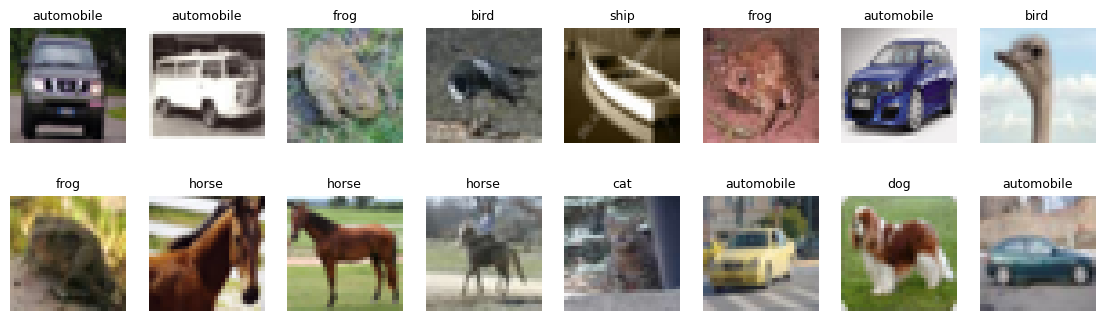

In [ ]:
(x_trainval, y_trainval), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_trainval, y_test = y_trainval.ravel(), y_test.ravel()
class_names = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]
NUM_CLASSES = 10

# Стратифицированное разделение на обучающую и проверочную выборки
x_train, x_val, y_train, y_val = train_test_split(
    x_trainval, y_trainval, test_size=VAL_SIZE, stratify=y_trainval, random_state=SEED)

x_train, x_val, x_test = [a.astype("float32") for a in (x_train, x_val, x_test)]
y_train_oh = keras.utils.to_categorical(y_train, NUM_CLASSES)
y_val_oh   = keras.utils.to_categorical(y_val, NUM_CLASSES)
y_test_oh  = keras.utils.to_categorical(y_test, NUM_CLASSES)
print("train:", x_train.shape, "val:", x_val.shape, "test:", x_test.shape)

fig, ax = plt.subplots(2, 8, figsize=(14, 4))
for i, a in enumerate(ax.ravel()):
    a.imshow(x_train[i].astype("uint8")); a.set_title(class_names[y_train[i]], fontsize=9); a.axis("off")
plt.show()

### 2. Увеличение базы изображений: ImageDataGenerator
**Для скорости:** аугментация делается **один раз** до обучения, результат хранится в памяти (`uint8`). В эпохах CPU ничего не считает, GPU не простаивает.

База: 45000 -> 90000 изображений (34 с)


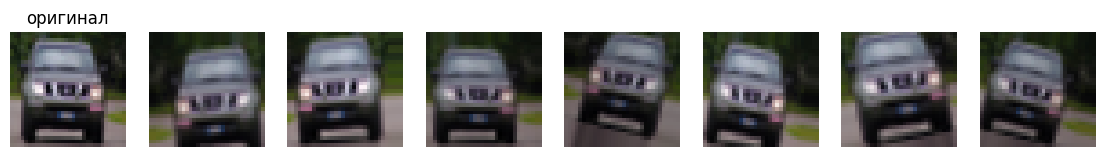

In [ ]:
# ---------- Параметры скорости (переопределяют значения выше) ----------
AUG_COPIES   = 1      # сколько аугментированных копий добавить (1 -> база x2)
BATCH_SIZE   = 256    # на GPU большой батч быстрее
TUNER_EPOCHS = 9      # Hyperband: 20 слишком долго; 9 даёт те же лучшие модели намного быстрее
MAX_TRIALS   = 8      # для bayesian / random

train_datagen = ImageDataGenerator(      # без rescale: нормализация внутри модели, на GPU
    rotation_range=ROTATION_RANGE,
    width_shift_range=WIDTH_SHIFT_RANGE,
    height_shift_range=HEIGHT_SHIFT_RANGE,
    zoom_range=ZOOM_RANGE,
    brightness_range=BRIGHTNESS_RANGE,
    horizontal_flip=HORIZONTAL_FLIP,
    fill_mode="nearest",
)

def augment_dataset(x, y, datagen, copies, chunk=2000):
    xs, ys = [x.astype("uint8")], [y]
    for _ in range(copies):
        flow = datagen.flow(x.astype("float32"), y, batch_size=chunk, shuffle=False)
        for i in range(len(flow)):
            xb, yb = flow[i]
            xs.append(np.clip(xb, 0, 255).astype("uint8")); ys.append(yb)
    return np.concatenate(xs), np.concatenate(ys)

t0 = time.time()
x_train_aug, y_train_aug = augment_dataset(x_train, y_train, train_datagen, AUG_COPIES)
print(f"База: {len(x_train)} -> {len(x_train_aug)} изображений ({time.time() - t0:.0f} с)")

sample = x_train[:1]
it = train_datagen.flow(sample, batch_size=1, seed=1)
fig, ax = plt.subplots(1, 8, figsize=(14, 2))
ax[0].imshow(sample[0].astype("uint8")); ax[0].set_title("оригинал"); ax[0].axis("off")
for a in ax[1:]:
    a.imshow(np.clip(next(it)[0], 0, 255).astype("uint8")); a.axis("off")
plt.show()

### 3. Модель и обучение базовой сети

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 323,946 (1.24 MB)

 Trainable params: 323,050 (1.23 MB)

 Non-trainable params: 896 (3.50 KB)

Epoch 1/10
352/352 - 45s - 129ms/step - accuracy: 0.5082 - loss: 1.3438 - val_accuracy: 0.2876 - val_loss: 2.3523 - learning_rate: 0.0010
Epoch 2/10
352/352 - 4s - 12ms/step - accuracy: 0.6592 - loss: 0.9570 - val_accuracy: 0.6796 - val_loss: 0.9044 - learning_rate: 0.0010
Epoch 3/10
352/352 - 4s - 12ms/step - accuracy: 0.7171 - loss: 0.8032 - val_accuracy: 0.7004 - val_loss: 0.8570 - learning_rate: 0.0010
Epoch 4/10
352/352 - 4s - 12ms/step - accuracy: 0.7540 - loss: 0.7055 - val_accuracy: 0.7546 - val_loss: 0.7174 - learning_rate: 0.0010
Epoch 5/10
352/352 - 4s - 12ms/step - accuracy: 0.7799 - loss: 0.6339 - val_accuracy: 0.7812 - val_loss: 0.6290 - learning_rate: 0.0010
Epoch 6/10
352/352 - 4s - 12ms/step - accuracy: 0.7969 - loss: 0.5851 - val_accuracy: 0.7454 - val_loss: 0.7464 - learning_rate: 0.0010
Epoch 7/10
352/352 - 4s - 12ms/step - accuracy: 0.8132 - loss: 0.5383 - val_accuracy: 0.7582 - val_loss: 0.7465 - learning_rate: 0.0010
Epoch 8/10
352/352 - 4s - 12ms/step - accuracy

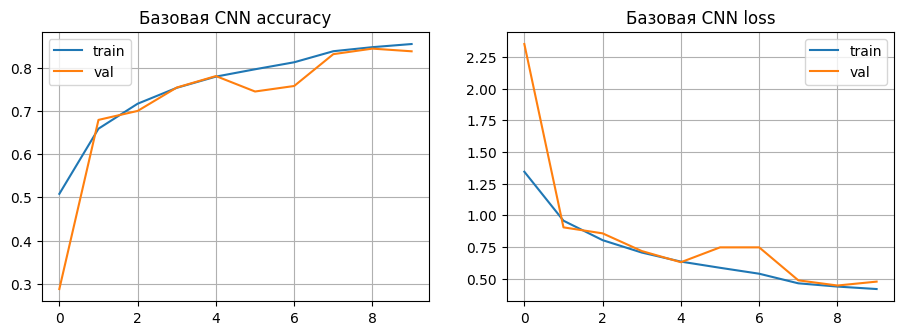

Базовая сеть: test accuracy = 0.8397; гиперпараметры: {'filters': 32, 'blocks': 3, 'dropout': 0.3, 'dense_units': 256, 'optimizer': 'adam', 'lr': 0.001}


In [ ]:
import warnings
warnings.filterwarnings("ignore", message="Skipping variable loading for optimizer")

def build_cnn(hp):
    filters  = hp.Choice("filters", [32, 64])
    n_blocks = hp.Int("blocks", 2, 3, default=3)
    dropout  = hp.Choice("dropout", [0.3, 0.2, 0.4])
    dense    = hp.Choice("dense_units", [256, 128])
    opt_name = hp.Choice("optimizer", ["adam", "adamw"])
    lr       = hp.Float("lr", 3e-4, 3e-3, sampling="log", default=1e-3)

    inp = keras.Input((32, 32, 3))
    x = layers.Rescaling(1. / 255)(inp)           # нормализация на GPU
    for b in range(n_blocks):
        for _ in range(2):
            x = layers.Conv2D(filters * 2 ** b, 3, padding="same", use_bias=False)(x)
            x = layers.BatchNormalization()(x)
            x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(dropout * 0.5)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dense, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32")(x)

    opt = {"adam": keras.optimizers.Adam, "adamw": keras.optimizers.AdamW}[opt_name](learning_rate=lr)
    model = keras.Model(inp, out)
    model.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def cbs(patience=4):
    return [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=patience, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)]

def plot_history(h, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    for a, m in zip(ax, ("accuracy", "loss")):
        a.plot(h.history[m], label="train"); a.plot(h.history["val_" + m], label="val")
        a.set_title(f"{title} {m}"); a.legend(); a.grid()
    plt.show()

base_hp = kt.HyperParameters()
base_model = build_cnn(base_hp)
base_model.summary()

t0 = time.time()
hist = base_model.fit(x_train_aug, y_train_aug, batch_size=BATCH_SIZE, epochs=EPOCHS,
                      validation_data=(x_val, y_val), callbacks=cbs(), verbose=2)
print(f"Время обучения: {time.time() - t0:.0f} с")
plot_history(hist, "Базовая CNN")
base_loss, base_acc = base_model.evaluate(x_test, y_test, batch_size=512, verbose=0)
print(f"Базовая сеть: test accuracy = {base_acc:.4f}; гиперпараметры: {base_hp.values}")

### 4. Подбор гиперпараметров (KerasTuner)

In [ ]:
common = dict(objective="val_accuracy", seed=SEED, directory="kt_cifar10", overwrite=True)
if TUNER_TYPE == "hyperband":
    tuner = kt.Hyperband(build_cnn, max_epochs=TUNER_EPOCHS, factor=3, hyperband_iterations=1,
                         project_name="hyperband", **common)
elif TUNER_TYPE == "bayesian":
    tuner = kt.BayesianOptimization(build_cnn, max_trials=MAX_TRIALS, project_name="bayes", **common)
else:
    tuner = kt.RandomSearch(build_cnn, max_trials=MAX_TRIALS, project_name="random", **common)
tuner.search_space_summary()

t0 = time.time()
kw = dict(batch_size=BATCH_SIZE, validation_data=(x_val, y_val),
          callbacks=[keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=2)], verbose=0)
if TUNER_TYPE != "hyperband":
    kw["epochs"] = TUNER_EPOCHS
tuner.search(x_train_aug, y_train_aug, **kw)
print(f"Поиск занял {(time.time() - t0) / 60:.1f} мин")
tuner.results_summary(3)

Search space summary
Default search space size: 6
filters (Choice)
{'default': 32, 'conditions': [], 'values': [32, 64], 'ordered': True}
blocks (Int)
{'default': 3, 'conditions': [], 'min_value': 2, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
dropout (Choice)
{'default': 0.3, 'conditions': [], 'values': [0.3, 0.2, 0.4], 'ordered': True}
dense_units (Choice)
{'default': 256, 'conditions': [], 'values': [256, 128], 'ordered': True}
optimizer (Choice)
{'default': 'adam', 'conditions': [], 'values': ['adam', 'adamw'], 'ordered': False}
lr (Float)
{'default': 0.001, 'conditions': [], 'min_value': 0.0003, 'max_value': 0.003, 'step': None, 'sampling': 'log'}
Поиск занял 19.2 мин
Results summary
Results in kt_cifar10/hyperband
Showing 3 best trials
Objective(name="val_accuracy", direction="max")

Trial 0018 summary
Hyperparameters:
filters: 32
blocks: 3
dropout: 0.4
dense_units: 256
optimizer: adamw
lr: 0.00253182750284068
tuner/epochs: 9
tuner/initial_epoch: 3
tuner/bracket: 1
tuner/rou

### 5. Три лучшие модели


===== Модель #1: {'filters': 32, 'blocks': 3, 'dropout': 0.4, 'dense_units': 256, 'optimizer': 'adamw', 'lr': 0.00253182750284068, 'tuner/epochs': 9, 'tuner/initial_epoch': 3, 'tuner/bracket': 1, 'tuner/round': 1, 'tuner/trial_id': '0016'}


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 970,048 (3.70 MB)

 Trainable params: 323,050 (1.23 MB)

 Non-trainable params: 896 (3.50 KB)

 Optimizer params: 646,102 (2.46 MB)

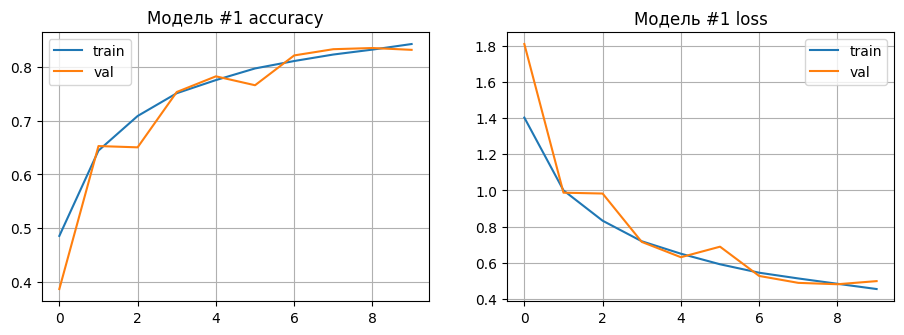


===== Модель #2: {'filters': 32, 'blocks': 3, 'dropout': 0.4, 'dense_units': 128, 'optimizer': 'adamw', 'lr': 0.000529179747079077, 'tuner/epochs': 9, 'tuner/initial_epoch': 3, 'tuner/bracket': 1, 'tuner/round': 1, 'tuner/trial_id': '0014'}


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_12 (Activation)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_13 (Activation)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_14 (Activation)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 916,672 (3.50 MB)

 Trainable params: 305,258 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

 Optimizer params: 610,518 (2.33 MB)

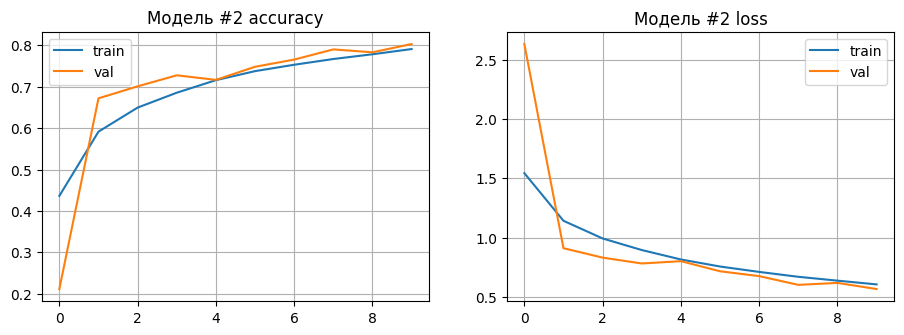


===== Модель #3: {'filters': 64, 'blocks': 2, 'dropout': 0.4, 'dense_units': 128, 'optimizer': 'adamw', 'lr': 0.0006202352479192391, 'tuner/epochs': 9, 'tuner/initial_epoch': 0, 'tuner/bracket': 0, 'tuner/round': 0}


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 32, 32, 64)     │         1,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_16 (Activation)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_17 (Activation)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_18 (Activation)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_19 (Activation)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 835,808 (3.19 MB)

 Trainable params: 278,346 (1.06 MB)

 Non-trainable params: 768 (3.00 KB)

 Optimizer params: 556,694 (2.12 MB)

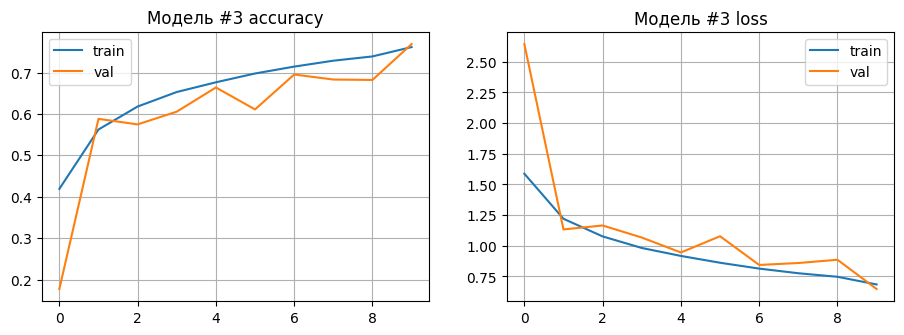

,Модель,val_acc,test_acc,test_loss,параметров,filters,blocks,dropout,dense_units,optimizer,lr,tuner/epochs,tuner/initial_epoch,tuner/bracket,tuner/round,tuner/trial_id
0,#1,0.8358,0.8192,0.5372,323946,32.0,3.0,0.4,256.0,adamw,0.0025,9.0,3.0,1.0,1.0,0016
1,#2,0.8032,0.7943,0.5906,306154,32.0,3.0,0.4,128.0,adamw,0.0005,9.0,3.0,1.0,1.0,0014
2,#3,0.7692,0.7642,0.6698,279114,64.0,2.0,0.4,128.0,adamw,0.0006,9.0,0.0,0.0,0.0,NaN
3,базовая,0.8448,0.8397,0.4730,323946,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
best_hps = tuner.get_best_hyperparameters(3)
top_models, rows = [], []
for rank, hp in enumerate(best_hps, 1):
    print(f"\n===== Модель #{rank}: {hp.values}")
    model = build_cnn(hp)
    h = model.fit(x_train_aug, y_train_aug, batch_size=BATCH_SIZE, epochs=EPOCHS,
                  validation_data=(x_val, y_val), callbacks=cbs(), verbose=0)
    loss, acc = model.evaluate(x_test, y_test, batch_size=512, verbose=0)
    model.summary()
    plot_history(h, f"Модель #{rank}")
    top_models.append(model)
    rows.append({"Модель": f"#{rank}", "val_acc": max(h.history["val_accuracy"]), "test_acc": acc,
                 "test_loss": loss, "параметров": model.count_params(), **hp.values})

results = pd.DataFrame(rows)
results.loc[len(results)] = {"Модель": "базовая", "val_acc": max(hist.history["val_accuracy"]),
                             "test_acc": base_acc, "test_loss": base_loss,
                             "параметров": base_model.count_params()}
display(results.round(4))

### 6. Лучшая архитектура и результаты

Лучшая модель: #1, гиперпараметры: {'filters': 32, 'blocks': 3, 'dropout': 0.4, 'dense_units': 256, 'optimizer': 'adamw', 'lr': 0.00253182750284068, 'tuner/epochs': 9, 'tuner/initial_epoch': 3, 'tuner/bracket': 1, 'tuner/round': 1, 'tuner/trial_id': '0016'}
              precision    recall  f1-score   support

    airplane     0.6936    0.9350    0.7964      1000
  automobile     0.9595    0.8770    0.9164      1000
        bird     0.7535    0.7430    0.7482      1000
         cat     0.6490    0.7210    0.6831      1000
        deer     0.8440    0.7630    0.8015      1000
         dog     0.8699    0.6620    0.7518      1000
        frog     0.9004    0.8230    0.8600      1000
       horse     0.8158    0.8900    0.8513      1000
        ship     0.9293    0.8670    0.8971      1000
       truck     0.8776    0.9110    0.8940      1000

    accuracy                         0.8192     10000
   macro avg     0.8293    0.8192    0.8200     10000
weighted avg     0.8293    0.8192    0

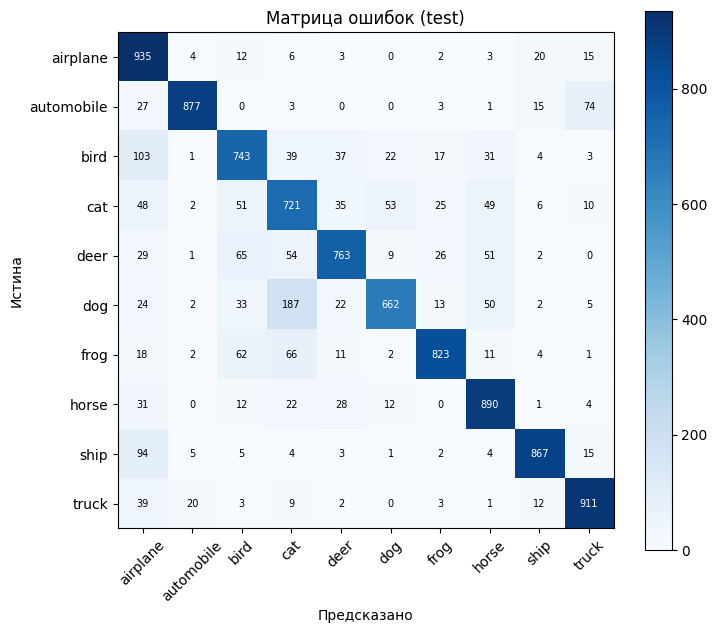

In [ ]:
best_i = int(np.argmax([r["test_acc"] for r in rows]))
best_model = top_models[best_i]
print(f"Лучшая модель: #{best_i + 1}, гиперпараметры: {best_hps[best_i].values}")
best_model.save("best_cifar10.keras")

y_pred = best_model.predict(x_test, batch_size=512, verbose=0).argmax(1)
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 7)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(10), class_names, rotation=45); plt.yticks(range(10), class_names)
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xlabel("Предсказано"); plt.ylabel("Истина"); plt.title("Матрица ошибок (test)"); plt.show()